# Регресія тривалості ДТП — FMRegressor та AFTSurvivalRegression

*Дані з `regression_data_preparation.ipynb`; ціль `Log_Duration = log1p(Duration_Minutes)`.


## Етап 0. Середовище

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler, Bucketizer
from pyspark.ml.regression import FMRegressor, AFTSurvivalRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

ROOT = Path.cwd() if (Path.cwd() / 'main.py').exists() else Path.cwd().parent
DATA = ROOT / 'data' / 'processed' / 'regression'
OUT = ROOT / 'data' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TUNE_ROWS = int(os.environ.get('TUNE_ROWS', '80000'))
TRAIN_FRACTION = float(os.environ.get('TRAIN_FRACTION', '1'))
SHAP_ROWS = int(os.environ.get('SHAP_ROWS', '3000'))
CV_FOLDS = 5
assert (DATA / 'metadata.json').exists(), 'Спочатку завершіть regression_data_preparation.ipynb'
os.environ['PYSPARK_PYTHON'] = sys.executable
spark = (SparkSession.builder.appName('US-Accidents-regression-yh')
         .master('local[2]')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.driver.memory', '8g')
         .config('spark.driver.maxResultSize', '2g')
         .config('spark.ui.showConsoleProgress','false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark', spark.version)

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.1


In [2]:
print("Spark працює:", spark.range(10).count())

Spark працює: 10


## Етап 1. Завантаження та огляд train / valid / test

In [3]:
meta = json.loads((DATA / 'metadata.json').read_text(encoding='utf-8'))
FEATURES = meta['feature_names']
SAFE = [f'f{i}' for i in range(len(FEATURES))]

def read_split(name):
    df = spark.read.parquet(str(DATA / name))
    return df.select('ID', F.col('Log_Duration').cast('double').alias('label'),
                     F.col('Duration_Minutes').cast('double').alias('minutes'),
                     *[F.col('`'+col.replace('`','``')+'`').cast('double').alias(safe)
                       for col, safe in zip(FEATURES, SAFE)])
raw = {s: read_split(s) for s in ('train','valid','test')}
if TRAIN_FRACTION < 1:
    raw['train'] = raw['train'].sample(False, TRAIN_FRACTION, SEED)
for name, df in raw.items():
    print(name, 'columns:', len(df.columns), 'sample:')
    display(df.select('label','minutes',*SAFE[:4]).limit(4).toPandas())

train columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.110874,60.00,-0.364908,-1.367240,-0.557499,1.399576
1,3.410157,29.27,0.545562,0.018898,-0.557499,1.825403
2,4.119362,60.52,1.133219,0.417321,-0.557499,0.122094
3,3.827554,44.95,-0.009973,0.465663,-0.557499,1.186662


valid columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.699753,108.92,-0.236919,0.783983,-0.557499,0.335007
1,4.067658,57.42,-0.392088,0.869631,-0.557499,0.867292
2,4.110874,60.00,-0.406671,-1.351524,-0.557499,-0.085497
3,3.842244,45.63,-1.197667,-0.163081,-0.557499,0.760835


test columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.678235,106.58,-0.077927,0.938835,-0.557499,0.601149
1,3.414443,29.40,0.508761,0.287952,-0.557499,0.281779
2,3.828641,45.00,-0.437945,-1.333911,-0.557499,0.239196
3,5.473404,237.27,0.282688,0.998558,-0.557499,0.122094


In [4]:
assembler = VectorAssembler(inputCols=SAFE, outputCol='features', handleInvalid='error')

data = {s: assembler.transform(df.filter(F.col('label') > 0))
        .select('ID', 'label', 'minutes', 'features')
        .withColumn('censor', F.lit(1.0)).persist(StorageLevel.MEMORY_AND_DISK)
        for s, df in raw.items()}
counts = {s: d.count() for s,d in data.items()}
print('Кількість записів:', counts)
for s,d in data.items():
    display(d.select('label','minutes').describe().toPandas().assign(split=s))

Кількість записів: {'train': 4496355, 'valid': 642217, 'test': 1282718}


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,4496355,4496355,train
1,mean,4.171715825263084,84.93995044205391,train
2,stddev,0.7090692169755293,82.066547438215,train
3,min,0.7975071958841881,1.22,train
4,max,6.610022870676855,741.5,train


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,642217,642217,valid
1,mean,4.169323671585825,84.69043192565663,valid
2,stddev,0.7083738755160895,81.74647069992469,valid
3,min,1.6094379124341003,4.0,valid
4,max,6.610022870676855,741.5,valid


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,1282718,1282718,test
1,mean,4.170339048138543,84.82113913580874,test
2,stddev,0.7092788299415512,81.85619321409399,test
3,min,1.0715836162801904,1.92,test
4,max,6.610022870676855,741.5,test


## Етап 2. Стратифікована підвибірка, 5-fold CV, RMSE та MAE

In [5]:
edges = sorted(set(data['train'].approxQuantile('label', [i / 10 for i in range(1, 10)], 0.001)))
bucketizer = Bucketizer(splits=[-float('inf'), *edges, float('inf')], inputCol='label', outputCol='stratum')
stratified = bucketizer.transform(data['train'])
frac = min(1.0, TUNE_ROWS / max(1, counts['train']))
strata = list(range(len(edges)+1))
tune = (stratified.sampleBy('stratum', {float(x):frac for x in strata}, SEED)
        .withColumn('_r', F.rand(SEED))
        .withColumn('fold', ((F.row_number().over(Window.partitionBy('stratum').orderBy('_r'))-1) % CV_FOLDS).cast('int'))
        .drop('_r','stratum').persist(StorageLevel.MEMORY_AND_DISK))
print('CV sample:', tune.count())

CV sample: 80267


In [6]:
fm = FMRegressor(featuresCol='features', labelCol='label', predictionCol='prediction', seed=SEED)
aft = AFTSurvivalRegression(featuresCol='features', labelCol='label', censorCol='censor', predictionCol='prediction')
FAMILIES = {'FMRegressor': fm, 'AFTSurvivalRegression': aft}
GRID = {
    'FMRegressor': (ParamGridBuilder().addGrid(fm.factorSize,[4,8])
                    .addGrid(fm.regParam,[0.01,0.1]).addGrid(fm.maxIter,[30]).build()),
    'AFTSurvivalRegression': (ParamGridBuilder().addGrid(aft.maxIter,[40,80])
                              .addGrid(aft.tol,[1e-5,1e-6]).build())
}
def evaluate(predictions):
    row = predictions.select(F.avg(F.pow(F.col('prediction')-F.col('label'),2)).alias('mse'),
          F.avg(F.abs(F.col('prediction')-F.col('label'))).alias('mae'),
          F.avg(F.pow(F.expm1(F.col('prediction'))-F.col('minutes'),2)).alias('mse_min'),
          F.avg(F.abs(F.expm1(F.col('prediction'))-F.col('minutes'))).alias('mae_min')).first()
    return {'RMSE (log)': float(np.sqrt(row.mse)), 'MAE (log)':float(row.mae),
            'RMSE (хв)':float(np.sqrt(row.mse_min)), 'MAE (хв)':float(row.mae_min)}


In [7]:
BEST = {}
CV_TABLES = {}
for fam, estimator in FAMILIES.items():
    print('Підбір:',fam,flush=True)
    cv = CrossValidator(estimator=estimator, estimatorParamMaps=GRID[fam],
            evaluator=RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='rmse'),
            numFolds=CV_FOLDS, foldCol='fold', parallelism=1, seed=SEED)
    cvfit = cv.fit(tune)
    t = pd.DataFrame([{p.name:v for p,v in pm.items()} for pm in GRID[fam]])
    t['CV RMSE (log)'] = cvfit.avgMetrics
    CV_TABLES[fam] = t.sort_values('CV RMSE (log)')
    BEST[fam] = GRID[fam][int(np.argmin(cvfit.avgMetrics))]
    display(CV_TABLES[fam])

Підбір: FMRegressor


,factorSize,regParam,maxIter,CV RMSE (log)
1,4,0.10,30,7.371834
3,8,0.10,30,9.852082
0,4,0.01,30,36.838030
2,8,0.01,30,59.291917


Підбір: AFTSurvivalRegression


,maxIter,tol,CV RMSE (log)
3,80,0.000001,0.634636
2,80,0.000010,0.634639
1,40,0.000001,0.634671
0,40,0.000010,0.634671


## Етап 3. Навчання base та tuned на повному train

In [8]:
MODELS = {}
FIT_TIME = {}
for fam, est in FAMILIES.items():
    for kind, params in [('base', {}), ('tuned', BEST[fam])]:
        name = fam+' '+kind
        print('Навчання',name,flush=True)
        start = time.time()
        MODELS[name] = est.copy(params).fit(data['train'])
        FIT_TIME[name] = round(time.time()-start,1)
print('Час навчання, с:',FIT_TIME)
def metrics_table(split):
    results = {}
    for name,model in MODELS.items():
        results[name] = evaluate(model.transform(data[split]))
    return pd.DataFrame.from_dict(results,orient='index').sort_values('RMSE (log)')
TRAIN_RESULTS = metrics_table('train')
display(TRAIN_RESULTS.round(4))

Навчання FMRegressor base
Навчання FMRegressor tuned
Навчання AFTSurvivalRegression base
Навчання AFTSurvivalRegression tuned
Час навчання, с: {'FMRegressor base': 5281.5, 'FMRegressor tuned': 1050.5, 'AFTSurvivalRegression base': 151.1, 'AFTSurvivalRegression tuned': 139.4}


,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
AFTSurvivalRegression base,0.6345,0.4693,7.117670e+01,4.188640e+01
AFTSurvivalRegression tuned,0.6347,0.4693,7.119920e+01,4.190120e+01
FMRegressor tuned,7.7791,5.9803,4.016006e+96,1.949005e+93
FMRegressor base,12.6835,8.8383,6.780093e+144,3.198593e+141


## Етап 4. Валідація, вибір лідерів та графіки train/valid

In [9]:
VALID_RESULTS = metrics_table('valid')
LEADERS = {fam: VALID_RESULTS.loc[[x for x in MODELS if x.startswith(fam+' ')] , 'RMSE (log)'].idxmin()
           for fam in FAMILIES}
print('Лідери:', LEADERS)
display(VALID_RESULTS.round(4))
summary = pd.concat({'train':TRAIN_RESULTS,'valid':VALID_RESULTS},names=['split','model'])
display(summary.round(4))

Лідери: {'FMRegressor': 'FMRegressor tuned', 'AFTSurvivalRegression': 'AFTSurvivalRegression base'}


,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
AFTSurvivalRegression base,0.6349,0.4695,7.096520e+01,4.183820e+01
AFTSurvivalRegression tuned,0.6351,0.4696,7.099220e+01,4.185500e+01
FMRegressor tuned,7.8154,5.9878,7.602139e+95,9.486258e+92
FMRegressor base,12.8729,8.9009,1.548547e+135,1.941214e+132


RMSE (log)  MAE (log)      RMSE (хв)  \
split model                                                               
train AFTSurvivalRegression base       0.6345     0.4693   7.117670e+01   
      AFTSurvivalRegression tuned      0.6347     0.4693   7.119920e+01   
      FMRegressor tuned                7.7791     5.9803   4.016006e+96   
      FMRegressor base                12.6835     8.8383  6.780093e+144   
valid AFTSurvivalRegression base       0.6349     0.4695   7.096520e+01   
      AFTSurvivalRegression tuned      0.6351     0.4696   7.099220e+01   
      FMRegressor tuned                7.8154     5.9878   7.602139e+95   
      FMRegressor base                12.8729     8.9009  1.548547e+135   

                                        MAE (хв)  
split model                                       
train AFTSurvivalRegression base    4.188640e+01  
      AFTSurvivalRegression tuned   4.190120e+01  
      FMRegressor tuned             1.949005e+93  
      FMRegressor base             3.198593e+141  
valid AFTSurvivalRegression base    4.183820e+01  
      AFTSurvivalRegression tuned   4.185500e+01  
      FMRegressor tuned             9.486258e+92  
      FMRegressor base             1.941214e+132

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recomm

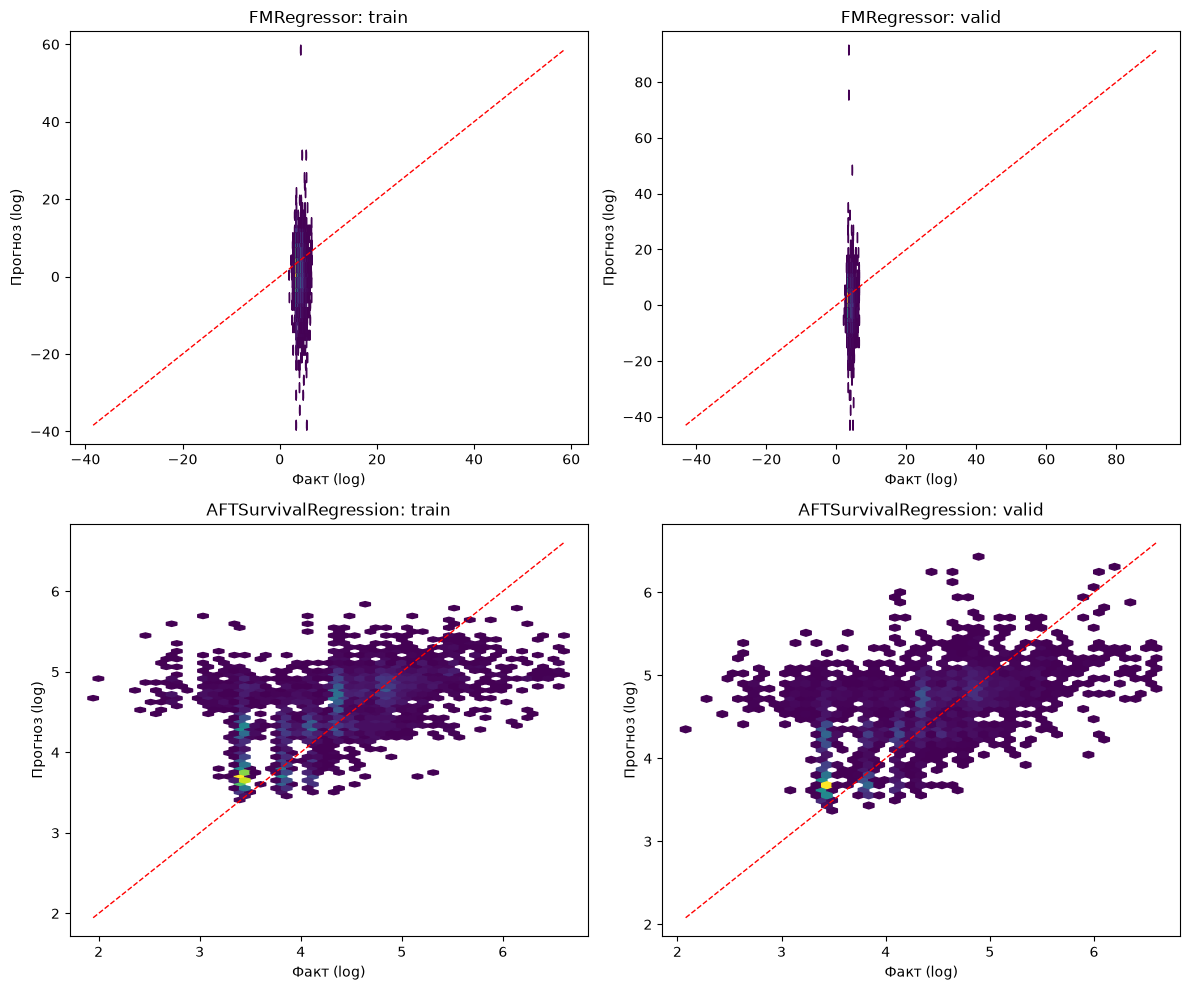

In [10]:
def prediction_sample(model, split, size=4000):
    d = model.transform(data[split]).select('label','prediction')
    return d.sample(False,min(1.,size/max(1,counts[split])),SEED).limit(size).toPandas()
fig, axs = plt.subplots(2,2,figsize=(12,10))
for i,(fam,name) in enumerate(LEADERS.items()):
    for j,split in enumerate(['train','valid']):
        p = prediction_sample(MODELS[name],split)
        ax=axs[i,j]
        ax.hexbin(p['label'],p['prediction'],gridsize=45,mincnt=1,cmap='viridis')
        lim=[min(p.min()),max(p.max())]
        ax.plot(lim,lim,'r--',lw=1)
        ax.set(title=f'{fam}: {split}',xlabel='Факт (log)',ylabel='Прогноз (log)')
plt.tight_layout(); plt.show()

## Етап 5. Фінальна оцінка на test

,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
FMRegressor,7.8393,5.9853,2.655546e+110,2.469681e+107
AFTSurvivalRegression,0.6359,0.4702,7.113600e+01,4.192250e+01


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recomm

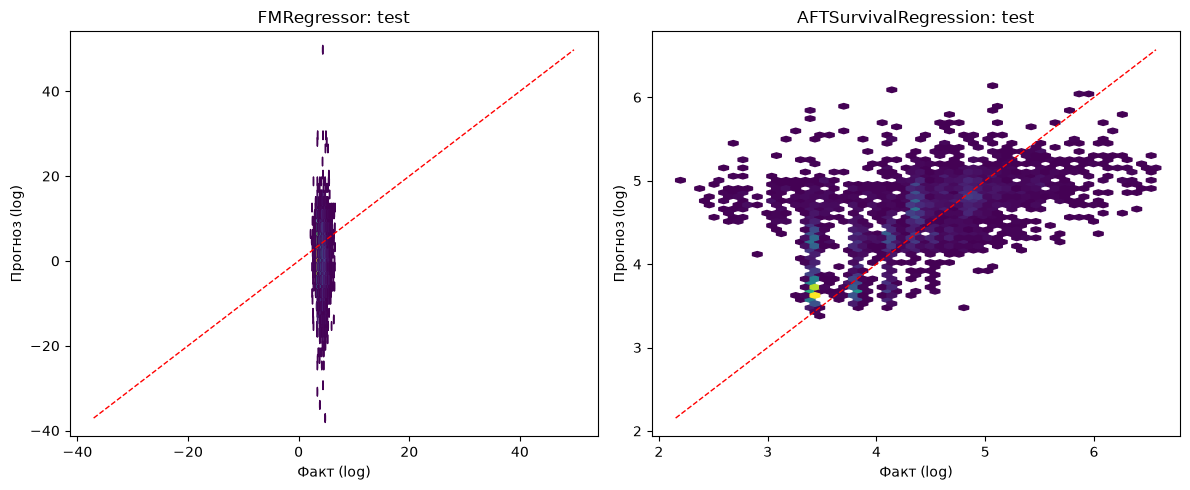

In [11]:
TEST_RESULTS = pd.DataFrame.from_dict(
    {fam:evaluate(MODELS[name].transform(data['test'])) for fam,name in LEADERS.items()},orient='index')
display(TEST_RESULTS.round(4))
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,(fam,name) in zip(axs,LEADERS.items()):
    p=prediction_sample(MODELS[name],'test')
    ax.hexbin(p['label'],p['prediction'],gridsize=50,mincnt=1,cmap='viridis')
    lim=[min(p.min()),max(p.max())]
    ax.plot(lim,lim,'r--',lw=1)
    ax.set(title=f'{fam}: test',xlabel='Факт (log)',ylabel='Прогноз (log)')
plt.tight_layout();plt.show()

## Етап 6. SHAP-аналіз

Для Spark FM/AFT немає вбудованого `TreeExplainer`. Тому для кожного лідера навчаємо **лінійну сурогатну модель на його прогнозах** і пояснюємо її `shap.LinearExplainer`. Це **SHAP сурогата**, а не точні SHAP-значення оригінальної Spark-моделі. Показуємо fidelity сурогата (R²); якщо він низький, інтерпретацію вважати ненадійною. Для сурогата достатньо 10 тис. рядків train; пояснюємо стратифіковані ~3000 test.

In [13]:
import shap
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

test_strat = bucketizer.transform(data['test'])
sample_frac = min(1.,SHAP_ROWS/max(1,counts['test']))
explain_df = (test_strat.sampleBy('stratum',{float(x):sample_frac for x in strata},SEED)
              .limit(SHAP_ROWS).select('features','label'))
from pyspark.ml.functions import vector_to_array
X_test_shap = np.stack([r['a'] for r in explain_df.select(vector_to_array('features').alias('a')).collect()])
assert len(X_test_shap)>0
train_small = data['train'].sample(False,min(1.,10000/max(1,counts['train'])),SEED).limit(10000)
X_bg = np.stack([r['a'] for r in train_small.select(vector_to_array('features').alias('a')).collect()])
print('SHAP test:',len(X_test_shap),'surrogate fit:',len(X_bg))

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP test: 3000 surrogate fit: 10000


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


FMRegressor — surrogate fidelity R²=0.649


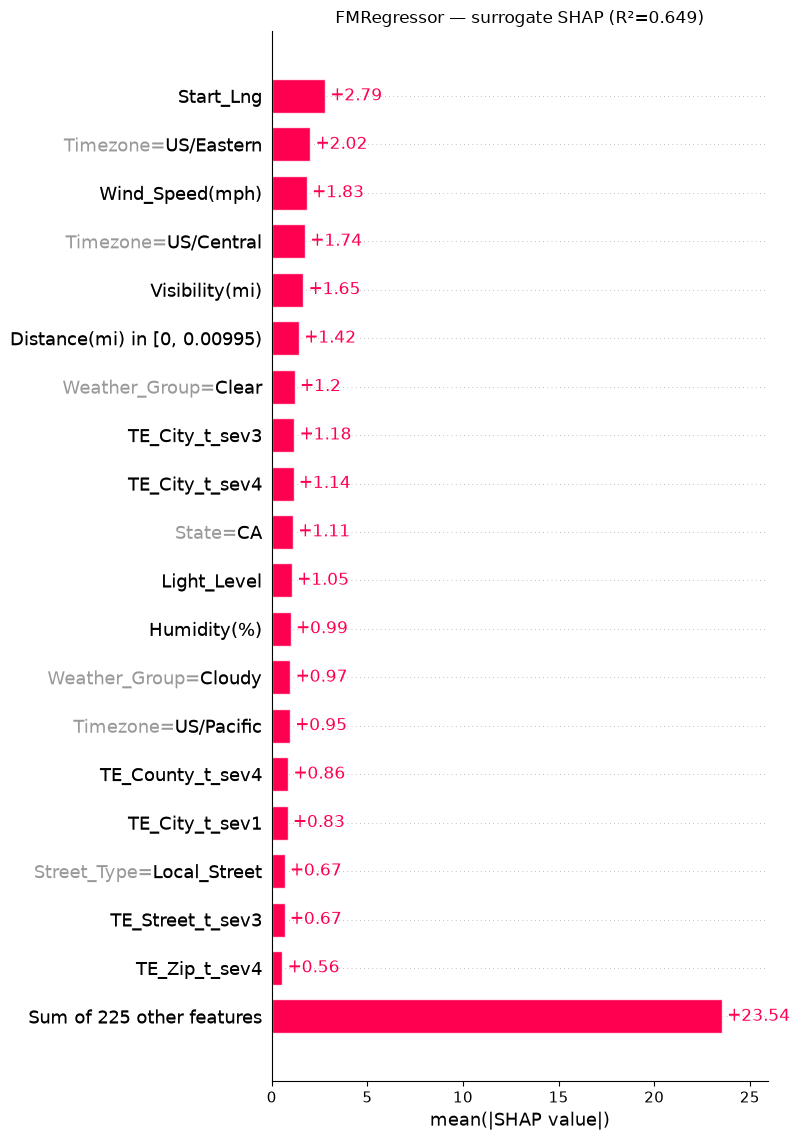

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


AFTSurvivalRegression — surrogate fidelity R²=0.999


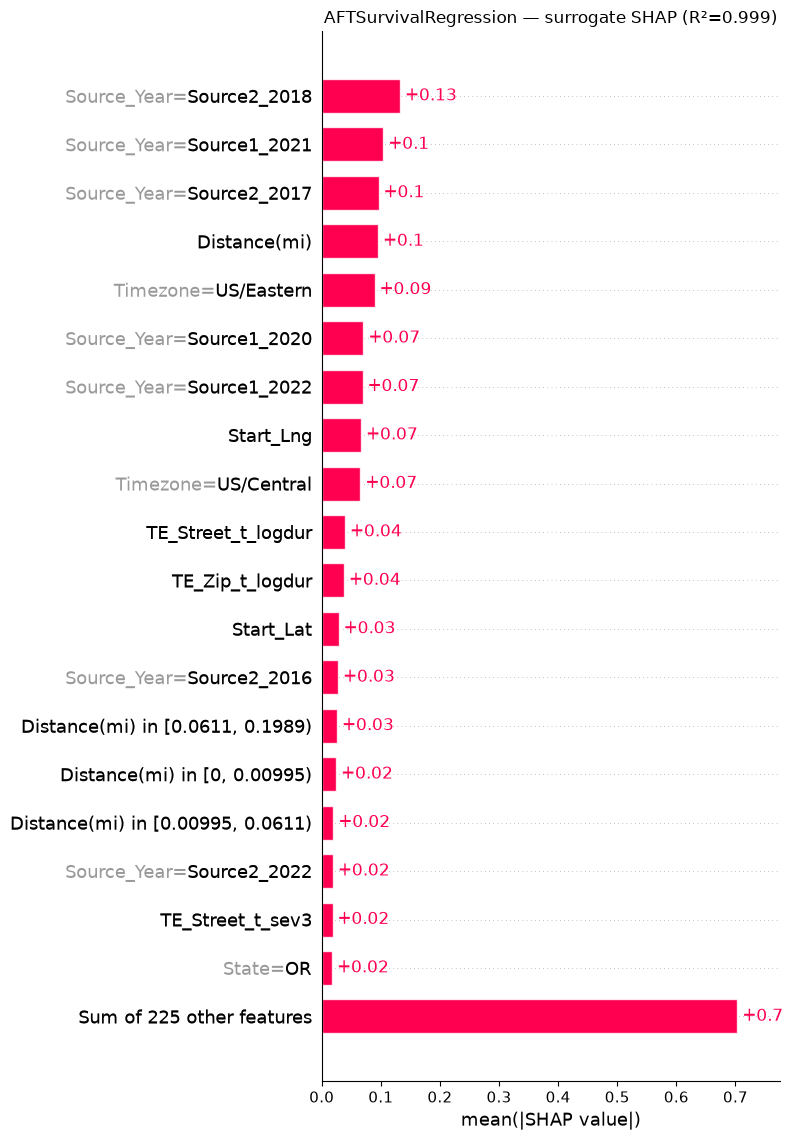

In [14]:
from pyspark.ml.linalg import Vectors
def get_prediction_vectors(model, frame):
    return np.array([r['prediction'] for r in model.transform(frame).select('prediction').collect()])

for fam,name in LEADERS.items():
    model=MODELS[name]
    train_target=get_prediction_vectors(model,train_small)
    test_target=get_prediction_vectors(model,explain_df)
    surrogate=Ridge(alpha=1.).fit(X_bg,train_target)
    fidelity=r2_score(test_target,surrogate.predict(X_test_shap))
    print(f'{fam} — surrogate fidelity R²={fidelity:.3f}')
    explainer=shap.LinearExplainer(surrogate,X_bg[:min(len(X_bg),200)])
    sv=explainer(X_test_shap)
    sv.feature_names=FEATURES
    shap.plots.bar(sv,max_display=20,show=False)
    plt.title(f'{fam} — surrogate SHAP (R²={fidelity:.3f})')
    plt.tight_layout();plt.show()

## Збереження обох лідерів

In [ ]:
for name in ("TRAIN_RESULTS", "TEST_RESULTS"):
    if name in globals():
        path = OUT / f"{name.lower()}.csv"
        globals()[name].to_csv(path)
        print("Збережено:", path)

print("Навчені моделі в пам'яті:", list(MODELS.keys()))

import pyspark
from pathlib import Path
jars = Path(pyspark.__file__).parent / "jars"
print("Версія Hadoop:", [p.name for p in jars.glob("hadoop-client-api-*.jar")])

Збережено: c:\Users\Admin\Desktop\US-Accidents-spark-project\data\models\train_results.csv
Збережено: c:\Users\Admin\Desktop\US-Accidents-spark-project\data\models\test_results.csv
Навчені моделі в пам'яті: ['FMRegressor base', 'FMRegressor tuned', 'AFTSurvivalRegression base', 'AFTSurvivalRegression tuned']
Версія Hadoop: ['hadoop-client-api-3.5.0.jar']
